<a href="https://colab.research.google.com/github/melaniela02/DSC_110/blob/main/Prediction_Model_Evaluation_Explanation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
X_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_train.csv')
X_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_test.csv')
y_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_train.csv')
y_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_test.csv')

#to prevent warning, converting the y from df to 1d series
y_train = y_train.squeeze()
y_test  = y_test.squeeze()

In [3]:
X_train.head() #checking work

,age,bmi,height_cm,systolic_bp,gender_Male,race_ethnicity_Black,race_ethnicity_Mexican American,race_ethnicity_Other,race_ethnicity_Other Hispanic,race_ethnicity_White,education_College grad,education_Do not know,education_High school,education_Less than 9th,education_Some college
0,0.321165,0.183891,-1.310308,0.446166,False,False,False,False,False,True,False,False,True,False,False
1,0.776425,-1.080948,-0.062021,-0.739931,False,False,False,False,False,True,False,False,True,False,False
2,0.548795,1.885958,1.061437,0.633444,False,True,False,False,False,False,True,False,False,False,False
3,1.459315,-0.009844,0.000959,-0.018182,False,False,False,False,False,True,False,False,False,True,False
4,-0.987708,-0.987256,0.494034,-0.178096,True,False,False,False,True,False,False,False,False,True,False


In [6]:
#build the random forets model
rf = RandomForestClassifier(random_state = 42)
rf.fit(X_train,y_train)

RandomForestClassifier(random_state=42)

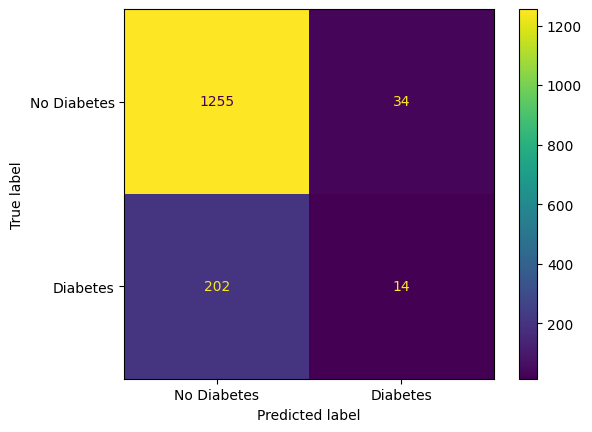

In [7]:
#Evaluate this model using the different evaluation metrics

y_pred = rf.predict(X_test) #each line on x test
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels = ['No Diabetes', 'Diabetes'])
plt.show() #to plot

In [9]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1289
           1       0.29      0.06      0.11       216

    accuracy                           0.84      1505
   macro avg       0.58      0.52      0.51      1505
weighted avg       0.78      0.84      0.80      1505



In [13]:
from sklearn.metrics import roc_auc_score
y_prob = rf.predict_proba(X_test)[:, 1]
print(f"AUC for Random Forest is {roc_auc_score(y_test, y_prob):.2f}")

AUC for Random Forest is 0.75


In [14]:
#play with threshold and generate the evaluation metrics
#change the threshold to 0.3
y_pred_03 = (y_prob >= 0.3). astype(int)
print(classification_report(y_test, y_pred_03))

              precision    recall  f1-score   support

           0       0.89      0.87      0.88      1289
           1       0.34      0.39      0.36       216

    accuracy                           0.80      1505
   macro avg       0.62      0.63      0.62      1505
weighted avg       0.81      0.80      0.81      1505



In [15]:
#change threshold from positive to 3.7 to watch what happens to specificity
y_pred_07 = (y_prob >= 0.7). astype(int)
print(classification_report(y_test, y_pred_07))

              precision    recall  f1-score   support

           0       0.86      0.99      0.92      1289
           1       0.11      0.00      0.01       216

    accuracy                           0.85      1505
   macro avg       0.48      0.50      0.46      1505
weighted avg       0.75      0.85      0.79      1505

